# Notebook 7 — Deployment & Prediction Pipeline

## 1. Overview

The model is finished. Notebook 4 selected the final model, and Notebook 5 evaluated it on the test set.

This notebook shows the next step: **using that frozen model to make predictions for new customers**.

Nothing is trained or tuned here. We simply take new customer information, pass it through the saved model, and turn the prediction into the business measures we defined in Notebook 6.

```text
New customer data
        ↓
Saved preprocessing
        ↓
Frozen Gradient Boosting model
        ↓
Predicted retirement fund
        ↓
Funding gap and funding ratio
        ↓
Proposed retirement readiness
        ↓
Power BI-ready customer table
```

The main output is:

`7/artifacts/07_powerbi_customer_predictions.csv`

This notebook uses synthetic demonstration customers. They are not a sample of real savers, and the readiness label is a business interpretation of a model prediction, not financial advice.


In [1]:
import hashlib
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

import sklearn
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.utils.validation import check_is_fitted

# --- Configuration -------------------------------------------------------
RANDOM_STATE = 42        # the seed used throughout this project
N_NEW_CUSTOMERS = 15     # size of the demonstration batch

# The proposed readiness bands defined in Notebook 6. Business-design
# assumptions, not a validated financial standard.
ON_TRACK_RATIO = 1.00
NEEDS_ATTENTION_RATIO = 0.75

# 04_final_model.joblib was pickled with this version of scikit-learn.
ARTIFACT_SKLEARN_VERSION = "1.6.1"

print("pandas       ", pd.__version__)
print("numpy        ", np.__version__)
print("scikit-learn ", sklearn.__version__)
if sklearn.__version__ != ARTIFACT_SKLEARN_VERSION:
    print(f"\nWARNING: 04_final_model.joblib was saved with scikit-learn "
          f"{ARTIFACT_SKLEARN_VERSION}. If it fails to load, install the matching "
          f"versions and restart:")
    print("    pip install scikit-learn==1.6.1 pandas==2.2.3 numpy==2.1.3")

# --- Project paths -------------------------------------------------------
# The project root is the folder that holds retirement_dataset_v2.csv. Each
# notebook keeps its outputs in its own numbered folder (4/artifacts, 7/artifacts).
CANDIDATE_ROOTS = [Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent]

PROJECT_ROOT = None
for candidate in CANDIDATE_ROOTS:
    if (candidate / "retirement_dataset_v2.csv").exists():
        PROJECT_ROOT = candidate
        break
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not find the project root (the folder holding retirement_dataset_v2.csv).")

MODEL_PATH = PROJECT_ROOT / "4" / "artifacts" / "04_final_model.joblib"
CONFIG_PATH = PROJECT_ROOT / "4" / "artifacts" / "04_final_model_config.json"
DATA_PATH = PROJECT_ROOT / "retirement_dataset_v2.csv"

# The saved pipeline rebuilds its feature-engineering step from src/, so that
# module must be importable before the model is loaded. Bytecode caching is
# turned off first, so importing it leaves no __pycache__ folder inside src/.
sys.dont_write_bytecode = True
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Notebook 7 writes only inside its own folder.
ARTIFACTS_DIR = Path.cwd() / "artifacts"
FIGURES_DIR = Path.cwd() / "figures"
ARTIFACTS_DIR.mkdir(exist_ok=True)
FIGURES_DIR.mkdir(exist_ok=True)

# Fingerprint every existing project file outside this notebook's folder.
# Section 14 re-hashes them to show that Notebook 7 changed nothing.
PROTECTED_FILES = sorted(
    path for path in PROJECT_ROOT.rglob("*")
    if path.is_file()
    and ".ipynb_checkpoints" not in path.parts
    and Path.cwd() not in path.parents
    and path.suffix in {".ipynb", ".py", ".csv", ".json", ".joblib", ".png", ".gz", ".md"}
)
PROTECTED_HASHES_BEFORE = {str(path): hashlib.sha256(path.read_bytes()).hexdigest()
                           for path in PROTECTED_FILES}

print()
print("Project root:", PROJECT_ROOT)
print("   model      ", MODEL_PATH.relative_to(PROJECT_ROOT))
print("   config     ", CONFIG_PATH.relative_to(PROJECT_ROOT))
print(f"Notebook 7 outputs -> {ARTIFACTS_DIR} and {FIGURES_DIR}")
print(f"Existing project files fingerprinted: {len(PROTECTED_HASHES_BEFORE)}")

pandas        2.2.3
numpy         2.1.3
scikit-learn  1.6.1

Project root: /home/claude/Claude- ML
   model       4/artifacts/04_final_model.joblib
   config      4/artifacts/04_final_model_config.json
Notebook 7 outputs -> /home/claude/Claude- ML/7/artifacts and /home/claude/Claude- ML/7/figures
Existing project files fingerprinted: 39


---
## 2. Load the Frozen Model

We load the model and its configuration exactly as Notebook 4 saved them.

The saved pipeline already contains the fitted preprocessing steps and the trained Gradient Boosting model. That means the same transformations used during training are applied when a new customer is scored.

There is no fitting here. We are only loading the finished model and calling it for prediction.

## 3. Verify the Model Is Frozen

Before using the model, we check that it is the expected trained model and that the configuration matches the final Notebook 4 setup.

This matters because an inference notebook should **use a model, not quietly change it**.


In [2]:
final_model = joblib.load(MODEL_PATH)
final_config = json.loads(CONFIG_PATH.read_text())

gradient_boosting = final_model.named_steps["model"]

print("Configuration read from 04_final_model_config.json")
print(f"   candidate            {final_config['candidate']}")
print(f"   algorithm            {type(gradient_boosting).__name__}")
print(f"   pipeline steps       {' -> '.join(final_model.named_steps)}")
print(f"   target scale         {final_config['target_scale']}")
print(f"   smearing correction  {final_config['smearing']} "
      f"(factor {final_config['smearing_factor']:.10f})")
print(f"   random_state         {final_config['random_state']}")
print(f"   model features       {final_config['n_model_features']}")
print(f"   training rows        {final_config['n_training_rows']:,}")
print("   hyperparameters:")
for key, value in final_config["model_params"].items():
    print(f"      {key:<18} {value}")

print(f"\nPrediction recipe: exp(log prediction) x {final_config['smearing_factor']:.10f}")

Configuration read from 04_final_model_config.json
   candidate            Tuned GB (log + smearing)
   algorithm            GradientBoostingRegressor
   pipeline steps       preprocess -> model
   target scale         log
   smearing correction  True (factor 1.0289327451)
   random_state         42
   model features       40
   training rows        23,880
   hyperparameters:
      subsample          0.8
      n_estimators       600
      min_samples_leaf   5
      max_depth          4
      learning_rate      0.05

Prediction recipe: exp(log prediction) x 1.0289327451


In [3]:
# check_is_fitted raises if the estimator has never been trained.
check_is_fitted(gradient_boosting)

hyperparameters_match = all(
    gradient_boosting.get_params()[key] == value
    for key, value in final_config["model_params"].items()
)

print(f"Estimator is a GradientBoostingRegressor   "
      f"{isinstance(gradient_boosting, GradientBoostingRegressor)}")
print(f"Estimator is already fitted                {hasattr(gradient_boosting, 'estimators_')}")
print(f"Trees inside the fitted model              {gradient_boosting.n_estimators_} "
      f"(configuration says {final_config['model_params']['n_estimators']})")
print(f"Hyperparameters match the configuration    {hyperparameters_match}")
print(f"Preprocessing step is already fitted       "
      f"{hasattr(final_model.named_steps['preprocess'], 'transformers_')}")

assert isinstance(gradient_boosting, GradientBoostingRegressor), "Unexpected estimator type."
assert hyperparameters_match, "Hyperparameters differ from the saved configuration."
assert gradient_boosting.n_estimators_ == final_config["model_params"]["n_estimators"], \
    "The fitted model does not have the number of trees the configuration records."

print("\nThe loaded object is the trained Notebook 4 model, used exactly as saved.")
print("Notebook 7 calls predict() only: no fit(), no fit_transform(), no tuning,")
print("no cross-validation, no model comparison and no recalculated smearing factor.")

Estimator is a GradientBoostingRegressor   True
Estimator is already fitted                True
Trees inside the fitted model              600 (configuration says 600)
Hyperparameters match the configuration    True
Preprocessing step is already fitted       True

The loaded object is the trained Notebook 4 model, used exactly as saved.
Notebook 7 calls predict() only: no fit(), no fit_transform(), no tuning,
no cross-validation, no model comparison and no recalculated smearing factor.


---
## 4. Define the New-Customer Input

A deployment pipeline needs new records that the model has not seen before.

For this demonstration, we generate 15 synthetic customer records using a fixed random seed. The input columns are taken from the model's expected raw feature structure, rather than being maintained as a second manual list.

There are three important rules:

- **The target is not included.** `Expected_Retirement_Fund` is what the model is predicting.
- **Target-derived fields are not included.** `Funding_Gap`, `Readiness_Score`, and `RetirementReady` depend on the outcome and would leak information into the model.
- **Engineered features are not supplied manually.** Features such as `YearsUntilRetirement` and `SalaryBasedContribution` are created inside the saved preprocessing pipeline.

`Retirement_Fund_Goal` is different. It is a raw input used by the trained model and is also used later as the business goal.

`Customer_ID` is only an identifier for reporting. It is kept out of the model input.

These customers are generated for demonstration only. Their summary statistics should not be interpreted as findings about a real population.


In [4]:
# The fitted pipeline records the raw columns it expects, so the required input
# structure is read from the model rather than typed out by hand.
preprocess = final_model.named_steps["preprocess"]
MODEL_INPUT_COLUMNS = list(preprocess.feature_names_in_)
COLUMNS_BY_TYPE = {name: list(columns) for name, _, columns in preprocess.transformers_}

print(f"The pipeline expects {len(MODEL_INPUT_COLUMNS)} raw customer columns "
      f"({len(COLUMNS_BY_TYPE['numeric'])} numeric, "
      f"{len(COLUMNS_BY_TYPE['categorical'])} categorical):")
print("   numeric      " + ", ".join(COLUMNS_BY_TYPE["numeric"]))
print("   categorical  " + ", ".join(COLUMNS_BY_TYPE["categorical"]))
print(f"\nIt then builds {final_config['n_model_features']} model features from them "
      f"internally, including the 5 engineered in src/feature_engineering.py.\n")

# Fifteen generated customers. Ranges are plain and readable; a few columns are
# derived from others so that each record is internally consistent (a bonus
# follows the salary, a retirement balance follows salary and years worked).
rng = np.random.default_rng(RANDOM_STATE)
n = N_NEW_CUSTOMERS

age = rng.integers(28, 59, n)                        # always below the retirement age below
salary = rng.uniform(45_000, 260_000, n).round(2)
years_experience = age - rng.integers(20, 27, n)     # career started between 20 and 26

new_customers = pd.DataFrame({
    "Customer_ID": [f"Customer_{number:03d}" for number in range(1, n + 1)],
    "Age": age,
    "Gender": rng.choice(["Female", "Male", "Non-binary"], n),
    "Education": rng.choice(["High School", "College", "Bachelor", "Master", "PhD"], n),
    "MaritalStatus": rng.choice(["Single", "Married", "Divorced", "Widowed"], n),
    "NumberOfChildren": rng.integers(0, 4, n),
    "EmploymentStatus": rng.choice(["Full-time", "Part-time", "Self-employed"], n,
                                   p=[0.72, 0.12, 0.16]),   # roughly the project's mix
    "YearsExperience": years_experience,
    "AnnualSalary": salary,
    "AnnualBonus": (salary * rng.uniform(0.00, 0.18, n)).round(2),
    "Savings": rng.uniform(5_000, 400_000, n).round(2),
    "CheckingBalance": rng.uniform(1_500, 40_000, n).round(2),
    "EmergencyFund": rng.uniform(0, 90_000, n).round(2),
    "InvestmentBalance": rng.uniform(0, 350_000, n).round(2),
    "RetirementAccountBalance": (salary * years_experience
                                 * rng.uniform(0.15, 0.55, n)).round(2),
    "Debt": rng.uniform(0, 45_000, n).round(2),
    "MortgageBalance": rng.uniform(0, 700_000, n).round(2),
    "OwnHouse": rng.choice(["Yes", "No"], n),
    "CreditScore": rng.integers(580, 830, n),
    "MonthlyExpenses": (salary / 12 * rng.uniform(0.35, 0.75, n)).round(2),
    "RiskTolerance": rng.integers(35, 90, n),
    "FinancialKnowledge": rng.choice(["Low", "Moderate", "High", "Expert"], n),
    "SavingsRate": rng.uniform(0.02, 0.16, n).round(4),
    "EmployerPension": rng.choice(["Yes", "No"], n),
    "DesiredRetirementAge": rng.integers(60, 69, n),
    "ExpectedAnnualReturn": rng.uniform(0.055, 0.105, n).round(4),
    "ExpectedInflation": rng.uniform(0.022, 0.038, n).round(4),
    "Retirement_Fund_Goal": rng.uniform(1_200_000, 7_500_000, n).round(2),
})

PREVIEW_COLUMNS = ["Customer_ID", "Age", "AnnualSalary", "SavingsRate",
                   "RetirementAccountBalance", "EmployerPension",
                   "DesiredRetirementAge", "Retirement_Fund_Goal"]

preview = new_customers[PREVIEW_COLUMNS].copy()
for column in ["AnnualSalary", "RetirementAccountBalance", "Retirement_Fund_Goal"]:
    preview[column] = preview[column].map(lambda value: f"{value:,.0f}")

print(f"{len(new_customers)} new customer records created: Customer_ID plus the "
      f"{len(MODEL_INPUT_COLUMNS)} raw columns the pipeline expects.\n")
print(preview.to_string(index=False))

The pipeline expects 27 raw customer columns (20 numeric, 7 categorical):
   numeric      Age, NumberOfChildren, YearsExperience, AnnualSalary, AnnualBonus, Savings, CheckingBalance, EmergencyFund, InvestmentBalance, RetirementAccountBalance, Debt, MortgageBalance, CreditScore, MonthlyExpenses, RiskTolerance, SavingsRate, DesiredRetirementAge, ExpectedAnnualReturn, ExpectedInflation, Retirement_Fund_Goal
   categorical  Gender, Education, MaritalStatus, EmploymentStatus, OwnHouse, FinancialKnowledge, EmployerPension

It then builds 40 model features from them internally, including the 5 engineered in src/feature_engineering.py.

15 new customer records created: Customer_ID plus the 27 raw columns the pipeline expects.

 Customer_ID  Age AnnualSalary  SavingsRate RetirementAccountBalance EmployerPension  DesiredRetirementAge Retirement_Fund_Goal
Customer_001   30       72,544       0.1361                  174,294              No                    62            6,107,677
Customer_002   

---
## 5. Validate the Input Data

Before making a prediction, we check that the new records have the structure the model expects.

The checks cover the main problems that could make an inference result unreliable:

- missing required columns;
- unexpected columns;
- target or target-derived leakage;
- invalid missing values;
- unsuitable data types.

We also confirm that the generated records are not copies of records already present in the source dataset.

The goal is simple: **validate first, predict second.**


In [5]:
# The frame handed to the model: the required columns, in the required order,
# with Customer_ID deliberately left out.
X_new = new_customers[MODEL_INPUT_COLUMNS]

# Columns derived from the target. None of these may reach the model.
LEAKAGE_COLUMNS = ["Expected_Retirement_Fund", "Readiness_Score", "Funding_Gap",
                   "RetirementReady"]

missing_columns = [name for name in MODEL_INPUT_COLUMNS if name not in new_customers.columns]
unexpected_columns = [name for name in X_new.columns if name not in MODEL_INPUT_COLUMNS]
leaked_columns = [name for name in LEAKAGE_COLUMNS if name in new_customers.columns]

# None of the generated records may duplicate a row of the source dataset, which
# is what rules out any overlap with the test split.
source_data = pd.read_csv(DATA_PATH, usecols=MODEL_INPUT_COLUMNS)
rows_copied_from_source = len(X_new.merge(source_data, how="inner"))

input_checks = pd.DataFrame([
    ("All required model input columns are present", not missing_columns),
    ("No unexpected columns are passed to the model", not unexpected_columns),
    ("Columns are in the order the pipeline expects",
     list(X_new.columns) == MODEL_INPUT_COLUMNS),
    ("Customer_ID is not passed to the model", "Customer_ID" not in X_new.columns),
    ("No target or target-derived column is present", not leaked_columns),
    ("No missing values", int(X_new.isna().sum().sum()) == 0),
    ("Numeric columns hold numbers",
     bool(X_new[COLUMNS_BY_TYPE["numeric"]].map(np.isreal).all().all())),
    ("Categorical columns hold text",
     all(X_new[name].map(type).eq(str).all() for name in COLUMNS_BY_TYPE["categorical"])),
    ("Retirement goals are present and positive",
     bool((new_customers.Retirement_Fund_Goal > 0).all())),
    ("No record was copied from the source dataset", rows_copied_from_source == 0),
], columns=["Input check", "Passed"]).set_index("Input check")

print(f"Validating {len(X_new)} records against the pipeline's expected input\n")
print(input_checks.to_string())

assert input_checks.Passed.all(), "The new-customer input failed validation."
print("\nInput validation passed. The records are ready to score.")

Validating 15 records against the pipeline's expected input

                                               Passed
Input check                                          
All required model input columns are present     True
No unexpected columns are passed to the model    True
Columns are in the order the pipeline expects    True
Customer_ID is not passed to the model           True
No target or target-derived column is present    True
No missing values                                True
Numeric columns hold numbers                     True
Categorical columns hold text                    True
Retirement goals are present and positive        True
No record was copied from the source dataset     True

Input validation passed. The records are ready to score.


---
## 6. Generate Predictions

This is the main inference step.

Notebook 4 trained the model using the logarithm of the retirement-fund target. We therefore follow the same prediction recipe when scoring new customers:

1. The frozen model produces a prediction in log space.
2. `np.exp()` converts that prediction back to dollars.
3. The saved smearing factor corrects the back-transformation.

The smearing factor is loaded from the Notebook 4 configuration. It is **not recalculated from these customers**.

We cannot calculate an error for these customers because their actual future retirement funds are unknown. That is normal for inference: we are producing predictions for outcomes that have not yet been observed.


In [6]:
# The frozen pipeline runs preprocessing and the model in one call. Nothing is fitted.
smearing_factor = final_config["smearing_factor"]

log_predictions = final_model.predict(X_new)

predicted_dollars = log_predictions
if final_config["target_scale"] == "log":
    predicted_dollars = np.exp(log_predictions) * smearing_factor

recipe_view = pd.DataFrame({
    "Customer_ID": new_customers.Customer_ID,
    "Model output (log)": [f"{value:.4f}" for value in log_predictions],
    "exp(log) in $": [f"{value:,.0f}" for value in np.exp(log_predictions)],
    f"x {smearing_factor:.6f} in $": [f"{value:,.0f}" for value in predicted_dollars],
})

print(f"Scored {len(predicted_dollars)} customers with the frozen model.\n")
print("The prediction recipe, customer by customer (first five shown):")
print(recipe_view.head().to_string(index=False))
print(f"\nPredicted retirement fund   min ${predicted_dollars.min():,.0f}   "
      f"median ${np.median(predicted_dollars):,.0f}   max ${predicted_dollars.max():,.0f}")

Scored 15 customers with the frozen model.

The prediction recipe, customer by customer (first five shown):
 Customer_ID Model output (log) exp(log) in $ x 1.028933 in $
Customer_001            14.8224     2,737,084       2,816,275
Customer_002            15.9431     8,394,516       8,637,392
Customer_003            14.5030     1,988,689       2,046,228
Customer_004            16.2734    11,679,800      12,017,728
Customer_005            15.5325     5,568,014       5,729,112

Predicted retirement fund   min $2,046,228   median $6,041,018   max $12,017,728


---
## 7. Create Business Measures

The model produces the predicted retirement fund. The measures below are calculated afterward using simple business rules.

| Layer | Measure | Meaning |
|---|---|---|
| **Model output** | `Predicted_Retirement_Fund` | The amount estimated by the model |
| **Customer input** | `Retirement_Fund_Goal` | The customer's stated goal |
| **Business measure** | `Funding_Gap` | Goal minus predicted fund |
| **Business measure** | `Funding_Ratio` | Predicted fund divided by goal |
| **Business interpretation** | `Retirement_Readiness` | A proposed threshold-based classification |

A positive funding gap means the predicted fund is below the goal.

The readiness classification is **not produced by the machine-learning model**. It is a business rule applied to the model's prediction.

The 1.00 boundary follows the readiness rule already present in the dataset. The 0.75 boundary is an illustrative assumption from Notebook 6, not a validated financial standard.

If a goal is missing or not positive, a funding ratio cannot be calculated. In that case, the notebook leaves the ratio blank rather than creating a misleading value.


In [7]:
goal_is_valid = new_customers.Retirement_Fund_Goal > 0
goal = new_customers.Retirement_Fund_Goal

scored = pd.DataFrame({
    # --- customer characteristics, carried through for the dashboard --------
    "Customer_ID": new_customers.Customer_ID,
    "Age": new_customers.Age,
    "AnnualSalary": new_customers.AnnualSalary,
    "SavingsRate": new_customers.SavingsRate,
    "RetirementAccountBalance": new_customers.RetirementAccountBalance,
    "EmploymentStatus": new_customers.EmploymentStatus,
    "Education": new_customers.Education,
    "EmployerPension": new_customers.EmployerPension,
    # Same definition as src/feature_engineering.py, reported here for segmentation.
    "YearsUntilRetirement": new_customers.DesiredRetirementAge - new_customers.Age,
    # --- model output -------------------------------------------------------
    "Predicted_Retirement_Fund": predicted_dollars.round(2),
    # --- business input -----------------------------------------------------
    "Retirement_Fund_Goal": goal,
})

# --- business-derived measures, calculated after the prediction -------------
scored["Funding_Gap"] = np.where(
    goal_is_valid, goal - scored.Predicted_Retirement_Fund, np.nan).round(2)
scored["Funding_Ratio"] = np.where(
    goal_is_valid, scored.Predicted_Retirement_Fund / goal, np.nan).round(4)

READINESS_BINS = [-np.inf, NEEDS_ATTENTION_RATIO, ON_TRACK_RATIO, np.inf]
READINESS_LABELS = ["Significant Gap", "Needs Attention", "On Track"]

scored["Retirement_Readiness"] = pd.cut(
    scored.Funding_Ratio, bins=READINESS_BINS, labels=READINESS_LABELS, right=False)
# A customer without a usable goal gets no band rather than a misleading one.
scored["Retirement_Readiness"] = (scored.Retirement_Readiness
                                  .cat.add_categories("No Goal Recorded")
                                  .fillna("No Goal Recorded"))

print(f"Customers with a usable retirement goal: "
      f"{int(goal_is_valid.sum())} of {len(scored)}\n")
print("MODEL OUTPUT")
print("   Predicted_Retirement_Fund   the only number the model produces\n")
print("BUSINESS-DERIVED MEASURES (calculated after the prediction, not learned)")
print("   Funding_Gap                 Retirement_Fund_Goal - Predicted_Retirement_Fund")
print("   Funding_Ratio               Predicted_Retirement_Fund / Retirement_Fund_Goal")
print(f"   Retirement_Readiness        On Track at or above {ON_TRACK_RATIO:.2f}, "
      f"Needs Attention from {NEEDS_ATTENTION_RATIO:.2f}, otherwise Significant Gap")

Customers with a usable retirement goal: 15 of 15

MODEL OUTPUT
   Predicted_Retirement_Fund   the only number the model produces

BUSINESS-DERIVED MEASURES (calculated after the prediction, not learned)
   Funding_Gap                 Retirement_Fund_Goal - Predicted_Retirement_Fund
   Funding_Ratio               Predicted_Retirement_Fund / Retirement_Fund_Goal
   Retirement_Readiness        On Track at or above 1.00, Needs Attention from 0.75, otherwise Significant Gap


---
## 8. Review the Scored Customers

This table brings the complete scoring result together: the customer information, the model's prediction, and the business measures calculated from that prediction.

It is the same type of customer-level information that a business dashboard will eventually display.

## 9. Simple Business Summary

The summary below describes only the 15 generated demonstration customers.

It is useful for checking the scoring pipeline, but it is **not a population-level result** and should not be interpreted as a statement about real customers.


In [8]:
DISPLAY_COLUMNS = ["Customer_ID", "Age", "AnnualSalary", "YearsUntilRetirement",
                   "EmployerPension", "Predicted_Retirement_Fund",
                   "Retirement_Fund_Goal", "Funding_Gap", "Funding_Ratio",
                   "Retirement_Readiness"]

display_table = scored[DISPLAY_COLUMNS].copy()
for column in ["AnnualSalary", "Predicted_Retirement_Fund", "Retirement_Fund_Goal",
               "Funding_Gap"]:
    display_table[column] = display_table[column].map(lambda value: f"{value:,.0f}")
display_table["Funding_Ratio"] = display_table.Funding_Ratio.map(lambda value: f"{value:.2f}")

print(f"Scored customers ({len(scored)} demonstration records)")
print(display_table.to_string(index=False))

readiness_counts = scored.Retirement_Readiness.value_counts().reindex(
    ["On Track", "Needs Attention", "Significant Gap"]).fillna(0).astype(int)
customers_short = int((scored.Funding_Gap > 0).sum())

summary = pd.DataFrame([
    ("Customers scored", f"{len(scored):,}"),
    ("Average predicted retirement fund", f"${scored.Predicted_Retirement_Fund.mean():,.0f}"),
    ("Median predicted retirement fund", f"${scored.Predicted_Retirement_Fund.median():,.0f}"),
    ("Average retirement fund goal", f"${scored.Retirement_Fund_Goal.mean():,.0f}"),
    ("Average funding ratio", f"{scored.Funding_Ratio.mean():.2f}"),
    ("Median funding ratio", f"{scored.Funding_Ratio.median():.2f}"),
    ("Customers with a projected funding gap", f"{customers_short}"),
    ("Share with a projected funding gap", f"{customers_short / len(scored) * 100:.1f}%"),
    ("Total projected shortfall", f"${scored.Funding_Gap.clip(lower=0).sum():,.0f}"),
    ("Proposed band: On Track", f"{readiness_counts['On Track']}"),
    ("Proposed band: Needs Attention", f"{readiness_counts['Needs Attention']}"),
    ("Proposed band: Significant Gap", f"{readiness_counts['Significant Gap']}"),
], columns=["Measure", "Value"]).set_index("Measure")

print(f"\nSummary of this demonstration batch (descriptive, not a population finding)")
print(summary.to_string())

Scored customers (15 demonstration records)
 Customer_ID  Age AnnualSalary  YearsUntilRetirement EmployerPension Predicted_Retirement_Fund Retirement_Fund_Goal Funding_Gap Funding_Ratio Retirement_Readiness
Customer_001   30       72,544                    32              No                 2,816,275            6,107,677   3,291,402          0.46      Significant Gap
Customer_002   51      141,833                    17              No                 8,637,392            2,047,679  -6,589,713          4.22             On Track
Customer_003   48      124,722                    13              No                 2,046,228            4,577,229   2,531,001          0.45      Significant Gap
Customer_004   41      244,254                    27              No                12,017,728            4,439,604  -7,578,124          2.71             On Track
Customer_005   41      183,431                    27              No                 5,729,112            6,602,705     873,592          0.87

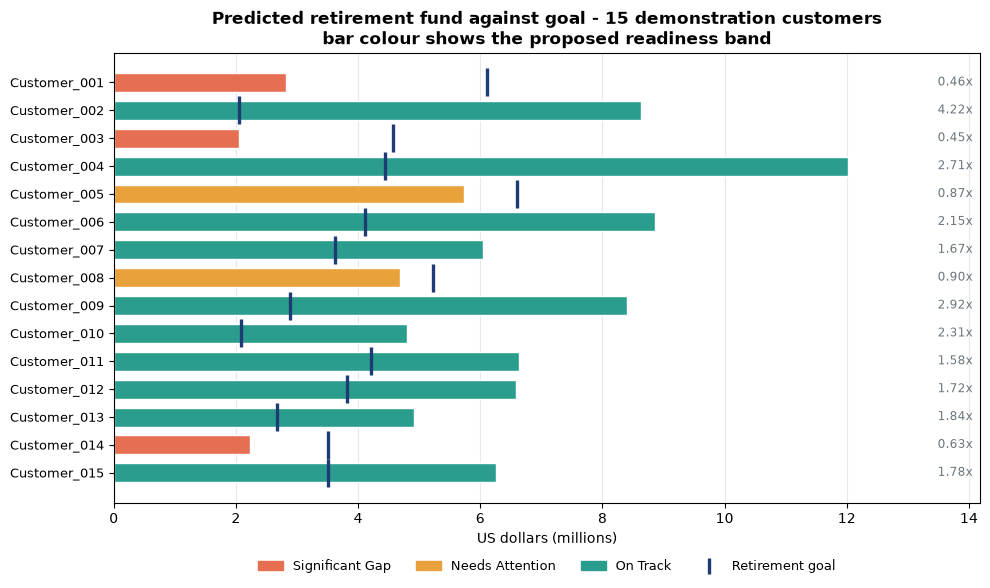

In [9]:
# --- FIGURE: predicted fund against goal, for the demonstration customers ----
NAVY, TEAL, AMBER, CORAL, SLATE = "#1F3B73", "#2A9D8F", "#E9A13B", "#E76F51", "#6C757D"
BAND_COLOURS = {"On Track": TEAL, "Needs Attention": AMBER,
                "Significant Gap": CORAL, "No Goal Recorded": SLATE}

positions = np.arange(len(scored))[::-1]
bar_colours = [BAND_COLOURS[band] for band in scored.Retirement_Readiness]

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(positions, scored.Predicted_Retirement_Fund / 1e6, color=bar_colours,
        edgecolor="white", height=0.68)
ax.scatter(scored.Retirement_Fund_Goal / 1e6, positions, color=NAVY, marker="|",
           s=420, linewidths=2.4, zorder=3)

# Leave a margin on the right for the funding-ratio labels.
largest = max(scored.Predicted_Retirement_Fund.max(), scored.Retirement_Fund_Goal.max()) / 1e6
ax.set_xlim(0, largest * 1.18)
for position, ratio in zip(positions, scored.Funding_Ratio):
    ax.text(largest * 1.17, position, f"{ratio:.2f}x", va="center", ha="right",
            fontsize=8.5, color=SLATE)

ax.set_yticks(positions)
ax.set_yticklabels(scored.Customer_ID, fontsize=9)
ax.set_xlabel("US dollars (millions)")
ax.set_title("Predicted retirement fund against goal - 15 demonstration customers\n"
             "bar colour shows the proposed readiness band",
             fontsize=12, fontweight="bold")
ax.grid(axis="x", color="#E8E8E8")
ax.set_axisbelow(True)

# One legend entry per band, plus the goal marker, placed below the chart.
handles = [plt.Rectangle((0, 0), 1, 1, color=BAND_COLOURS[band]) for band in READINESS_LABELS]
handles.append(plt.Line2D([0], [0], color=NAVY, marker="|", linestyle="None",
                          markersize=12, markeredgewidth=2.4))
ax.legend(handles, READINESS_LABELS + ["Retirement goal"], ncol=4, fontsize=9,
          frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.10))

plt.tight_layout()
plt.savefig(FIGURES_DIR / "07_predicted_vs_goal.png", dpi=300, bbox_inches="tight",
            facecolor="white")
plt.show()

---
## 10. Power BI Output

This is the main handoff from the Python project to Power BI.

The notebook saves one clean row per scored customer, containing the fields needed for the business dashboard:

`7/artifacts/07_powerbi_customer_predictions.csv`

The output supports three views planned in Notebook 6:

- **Portfolio view** — overall customer counts, predicted funds, funding ratios, and projected gaps.
- **Customer view** — an individual customer's profile, prediction, goal, gap, ratio, and readiness.
- **Segment view** — results across groups such as income, age, and years until retirement.

The file contains business-ready values rather than intermediate model calculations.

## 11. Data Dictionary for Power BI

The data dictionary explains what each output field means and where it comes from.

This distinction matters because a model output, a customer input, and a business rule should not be treated as the same thing.

The dictionary is saved as:

`7/artifacts/07_powerbi_data_dictionary.csv`


In [10]:
POWERBI_PATH = ARTIFACTS_DIR / "07_powerbi_customer_predictions.csv"
DICTIONARY_PATH = ARTIFACTS_DIR / "07_powerbi_data_dictionary.csv"

powerbi_table = scored.copy()
powerbi_table.to_csv(POWERBI_PATH, index=False)

# Column meaning and, just as importantly, where each column comes from.
COLUMN_NOTES = {
    "Customer_ID": ("Identifier", "Unique demonstration customer identifier. Not used by the model."),
    "Age": ("Customer input", "Customer age in years."),
    "AnnualSalary": ("Customer input", "Gross annual salary in dollars."),
    "SavingsRate": ("Customer input", "Share of salary directed to savings, as a decimal."),
    "RetirementAccountBalance": ("Customer input", "Current retirement account balance in dollars."),
    "EmploymentStatus": ("Customer input", "Employment status."),
    "Education": ("Customer input", "Highest education level."),
    "EmployerPension": ("Customer input", "Whether the employer provides a pension."),
    "YearsUntilRetirement": ("Customer input", "Desired retirement age minus current age."),
    "Predicted_Retirement_Fund": ("Model output", "Retirement fund in dollars predicted by the frozen Notebook 4 model."),
    "Retirement_Fund_Goal": ("Customer input", "The customer's own retirement-fund goal. Not predicted."),
    "Funding_Gap": ("Business rule", "Goal minus predicted fund. Positive means projected to fall short."),
    "Funding_Ratio": ("Business rule", "Predicted fund divided by goal. Blank where no valid goal exists."),
    "Retirement_Readiness": ("Business rule", "Proposed band: On Track at or above 1.00, Needs Attention from 0.75, otherwise Significant Gap."),
}
assert set(powerbi_table.columns) <= set(COLUMN_NOTES), "A column has no dictionary entry."

data_dictionary = pd.DataFrame([
    {"Column": column,
     "Source": COLUMN_NOTES[column][0],
     "Meaning": COLUMN_NOTES[column][1]}
    for column in powerbi_table.columns
])
data_dictionary.to_csv(DICTIONARY_PATH, index=False)

print(f"Power BI table   {POWERBI_PATH.name:<38} "
      f"{len(powerbi_table)} rows x {len(powerbi_table.columns)} columns   "
      f"{POWERBI_PATH.stat().st_size / 1024:.1f} KB")
print(f"Data dictionary  {DICTIONARY_PATH.name:<38} "
      f"{len(data_dictionary)} rows   {DICTIONARY_PATH.stat().st_size / 1024:.1f} KB")
print()
print(data_dictionary.to_string(index=False))

Power BI table   07_powerbi_customer_predictions.csv    15 rows x 14 columns   2.0 KB
Data dictionary  07_powerbi_data_dictionary.csv         14 rows   1.1 KB

                   Column         Source                                                                                         Meaning
              Customer_ID     Identifier                                Unique demonstration customer identifier. Not used by the model.
                      Age Customer input                                                                          Customer age in years.
             AnnualSalary Customer input                                                                 Gross annual salary in dollars.
              SavingsRate Customer input                                              Share of salary directed to savings, as a decimal.
 RetirementAccountBalance Customer input                                                  Current retirement account balance in dollars.
         Employmen

---
## 12. Prediction Example

This example follows one customer through the complete process:

**customer information → model prediction → goal → funding gap → funding ratio → readiness**

The customer is selected using a fixed rule, so the same demonstration is produced each time the notebook runs.

This is an example of how the scoring pipeline works. It is **not personalized financial advice**, and the readiness label should not be treated as a guaranteed outcome.

## 13. Deployment Concept

This notebook demonstrates the core of an inference pipeline. It is not a production application.

```text
New customer record
        ↓
Input validation
        ↓
Saved preprocessing
        ↓
Frozen model
        ↓
Predicted retirement fund
        ↓
Business calculations
        ↓
Power BI / application
```

The important design choice is that the fitted preprocessing and model are saved together. New customers therefore go through the same transformation process used during training.

The business rules are kept outside the model. This makes the distinction between **prediction** and **business interpretation** clear.

A full production system would require additional work such as real-world validation, monitoring, governance, privacy controls, and appropriate review before customer-facing use. Those activities are outside the scope of this project.

## 14. Final Verification

The final checks confirm that the inference pipeline works as intended:

- the saved final model loads successfully;
- the expected model configuration is preserved;
- no model fitting or tuning occurs;
- the new records contain no target leakage;
- predictions are valid;
- business measures are valid;
- the Power BI output is created correctly;
- predictions are reproducible;
- previous project files remain unchanged.

The goal is not just to produce a prediction, but to show that the **same frozen model can be used consistently on new data**.


In [11]:
# Deterministic choice: the customer nearest the median predicted fund.
example_position = int(np.argmin(np.abs(
    scored.Predicted_Retirement_Fund - scored.Predicted_Retirement_Fund.median())))

customer = scored.iloc[example_position]
raw_record = new_customers.iloc[example_position]

example = pd.Series({
    "Age": f"{raw_record.Age}",
    "Annual salary": f"${raw_record.AnnualSalary:,.0f}",
    "Savings rate": f"{raw_record.SavingsRate * 100:.1f}%",
    "Retirement account balance": f"${raw_record.RetirementAccountBalance:,.0f}",
    "Employment status": raw_record.EmploymentStatus,
    "Employer pension": raw_record.EmployerPension,
    "Years until retirement": f"{customer.YearsUntilRetirement}",
    "--- MODEL OUTPUT ---": "",
    "Predicted retirement fund": f"${customer.Predicted_Retirement_Fund:,.0f}",
    "--- BUSINESS MEASURES ---": "",
    "Retirement fund goal": f"${customer.Retirement_Fund_Goal:,.0f}",
    "Funding gap (goal - predicted)": f"${customer.Funding_Gap:,.0f}",
    "Funding ratio": f"{customer.Funding_Ratio:.2f}",
    "Proposed readiness band": str(customer.Retirement_Readiness),
}, name=customer.Customer_ID)
example.index.name = "Customer attribute"

print(example.to_string())
print(f"\nRead as: the model estimates this customer reaches "
      f"${customer.Predicted_Retirement_Fund:,.0f} against a goal of "
      f"${customer.Retirement_Fund_Goal:,.0f},")
print(f"a funding ratio of {customer.Funding_Ratio:.2f}, which the business rule places in "
      f"'{customer.Retirement_Readiness}'.")
print("The band is a prompt to look closer, not a conclusion and not financial advice.")

Customer attribute
Age                                        30
Annual salary                        $140,334
Savings rate                            10.4%
Retirement account balance           $331,531
Employment status                   Full-time
Employer pension                           No
Years until retirement                     31
--- MODEL OUTPUT ---                         
Predicted retirement fund          $6,041,018
--- BUSINESS MEASURES ---                    
Retirement fund goal               $3,626,064
Funding gap (goal - predicted)    $-2,414,954
Funding ratio                            1.67
Proposed readiness band              On Track

Read as: the model estimates this customer reaches $6,041,018 against a goal of $3,626,064,
a funding ratio of 1.67, which the business rule places in 'On Track'.
The band is a prompt to look closer, not a conclusion and not financial advice.


---
## 13. Deployment Concept

This notebook demonstrates the core of an inference pipeline. It is not a production application.

```text
New customer record
        ↓
Input validation
        ↓
Saved preprocessing
        ↓
Frozen model
        ↓
Predicted retirement fund
        ↓
Business calculations
        ↓
Power BI / application
```

The important design choice is that the fitted preprocessing and model are saved together. New customers therefore go through the same transformation process used during training.

The business rules are kept outside the model. This makes the distinction between **prediction** and **business interpretation** clear.

A full production system would require additional work such as real-world validation, monitoring, governance, privacy controls, and appropriate review before customer-facing use. Those activities are outside the scope of this project.

## 14. Final Verification

The final checks confirm that the inference pipeline works as intended:

- the saved final model loads successfully;
- the expected model configuration is preserved;
- no model fitting or tuning occurs;
- the new records contain no target leakage;
- predictions are valid;
- business measures are valid;
- the Power BI output is created correctly;
- predictions are reproducible;
- previous project files remain unchanged.

The goal is not just to produce a prediction, but to show that the **same frozen model can be used consistently on new data**.


In [12]:
# Reloading the model from disk must reproduce the predictions exactly.
reloaded_model = joblib.load(MODEL_PATH)
reloaded_dollars = reloaded_model.predict(X_new)
if final_config["target_scale"] == "log":
    reloaded_dollars = np.exp(reloaded_dollars) * final_config["smearing_factor"]

protected_hashes_after = {str(path): hashlib.sha256(path.read_bytes()).hexdigest()
                          for path in PROTECTED_FILES}
changed_files = [path for path, digest in PROTECTED_HASHES_BEFORE.items()
                 if protected_hashes_after.get(path) != digest]

saved_table = pd.read_csv(POWERBI_PATH)
REQUIRED_OUTPUT_COLUMNS = ["Customer_ID", "Predicted_Retirement_Fund",
                           "Retirement_Fund_Goal", "Funding_Gap", "Funding_Ratio",
                           "Retirement_Readiness"]

checks = [
    ("The saved final model loads successfully",
     isinstance(final_model, sklearn.pipeline.Pipeline)),
    ("The model is the expected Gradient Boosting model",
     isinstance(gradient_boosting, GradientBoostingRegressor)),
    ("The configuration matches Notebook 4 (hyperparameters, scale, smearing)",
     hyperparameters_match
     and final_config["target_scale"] == "log"
     and final_config["smearing"] is True
     and final_config["smearing_factor"] == 1.0289327450792438),
    ("No estimator is fitted in Notebook 7 (tree count unchanged after scoring)",
     gradient_boosting.n_estimators_ == final_config["model_params"]["n_estimators"]),
    ("The new-customer dataset does not contain the target or its derivatives",
     not [name for name in LEAKAGE_COLUMNS if name in new_customers.columns]),
    ("The new-customer dataset is not the test set (no row copied from the source data)",
     rows_copied_from_source == 0),
    ("Predictions contain no missing or infinite values",
     bool(np.isfinite(predicted_dollars).all()) and bool((predicted_dollars > 0).all())),
    ("Funding ratios are valid wherever the goal is valid",
     bool(np.isfinite(scored.loc[goal_is_valid, "Funding_Ratio"]).all())
     and bool(np.allclose(scored.loc[goal_is_valid, "Funding_Ratio"],
                          (scored.Predicted_Retirement_Fund / scored.Retirement_Fund_Goal)
                          [goal_is_valid], atol=1e-4))),
    ("The Power BI CSV exists", POWERBI_PATH.exists() and DICTIONARY_PATH.exists()),
    ("The output contains the required business columns",
     all(name in saved_table.columns for name in REQUIRED_OUTPUT_COLUMNS)),
    ("Output rows equal the number of new customers",
     len(saved_table) == N_NEW_CUSTOMERS == len(new_customers)),
    ("Reloading the saved model produces identical predictions",
     bool(np.array_equal(predicted_dollars, reloaded_dollars))),
    ("No existing notebook or project source file was modified", not changed_files),
]

verification = pd.DataFrame(checks, columns=["Check", "Passed"]).set_index("Check")
print(verification.to_string())

if changed_files:
    print("\nFiles that changed unexpectedly:")
    for path in changed_files:
        print(f"   {path}")

assert verification.Passed.all(), "One or more Notebook 7 checks failed."

print(f"\n{'=' * 78}")
print("All verification checks passed.")
print(f"{'=' * 78}")
print(f"   Model              {final_config['candidate']} (loaded, not trained)")
print(f"   Customers scored   {len(scored)} generated demonstration records")
print(f"   Power BI handoff   {POWERBI_PATH.relative_to(PROJECT_ROOT)}")
print(f"   Data dictionary    {DICTIONARY_PATH.relative_to(PROJECT_ROOT)}")
print(f"   Files protected    {len(PROTECTED_HASHES_BEFORE)} existing project files, "
      f"{len(changed_files)} changed")
print(f"   Next stage         the Power BI dashboard described in Notebook 6")
print("\n   Reminder: the dataset is synthetic and these fifteen customers are generated.")
print("   This notebook demonstrates the inference pipeline, not real customer outcomes.")

                                                                                   Passed
Check                                                                                    
The saved final model loads successfully                                             True
The model is the expected Gradient Boosting model                                    True
The configuration matches Notebook 4 (hyperparameters, scale, smearing)              True
No estimator is fitted in Notebook 7 (tree count unchanged after scoring)            True
The new-customer dataset does not contain the target or its derivatives              True
The new-customer dataset is not the test set (no row copied from the source data)    True
Predictions contain no missing or infinite values                                    True
Funding ratios are valid wherever the goal is valid                                  True
The Power BI CSV exists                                                              True
The output